In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp  

In [2]:
def get_tensordiff(TensorArray_tet,TensorArray_tet_ellip_minf,TensorArray_tet_ellip_n0, Omega):
    N=len(Omega)

    Eigenvaluestet=np.zeros((N,3),dtype=complex)
    Eigenvaluesminf=np.zeros((N,3),dtype=complex)
    Eigenvaluesn0=np.zeros((N,3),dtype=complex)

    for n in range(N):
    
        MPT=np.zeros((3,3),dtype=complex)
        MPT[0,0]=TensorArray_tet[n,0]
        MPT[0,1]=TensorArray_tet[n,1]
        MPT[0,2]=TensorArray_tet[n,2]
        MPT[1,0]=TensorArray_tet[n,3]
        MPT[1,1]=TensorArray_tet[n,4]
        MPT[1,2]=TensorArray_tet[n,5]
        MPT[2,0]=TensorArray_tet[n,6]
        MPT[2,1]=TensorArray_tet[n,7]
        MPT[2,2]=TensorArray_tet[n,8]
        reig,dum=np.linalg.eig(np.real(MPT))
        reig=np.sort(reig)
        ieig,dum=np.linalg.eig(np.imag(MPT))
        ieig=np.sort(ieig)
    
        Eigenvaluestet[n,:]=reig+1j*ieig
        MPT[0,0]=TensorArray_tet_ellip_minf[n,0]
        MPT[0,1]=TensorArray_tet_ellip_minf[n,1]
        MPT[0,2]=TensorArray_tet_ellip_minf[n,2]
        MPT[1,0]=TensorArray_tet_ellip_minf[n,3]
        MPT[1,1]=TensorArray_tet_ellip_minf[n,4]
        MPT[1,2]=TensorArray_tet_ellip_minf[n,5]
        MPT[2,0]=TensorArray_tet_ellip_minf[n,6]
        MPT[2,1]=TensorArray_tet_ellip_minf[n,7]
        MPT[2,2]=TensorArray_tet_ellip_minf[n,8]
        reig,dum=np.linalg.eig(np.real(MPT))
        reig=np.sort(reig)
        ieig,dum=np.linalg.eig(np.imag(MPT))
        ieig=np.sort(ieig)
        Eigenvaluesminf[n,:]=reig+1j*ieig
        

        MPT[0,0]=TensorArray_tet_ellip_n0[n,0]
        MPT[0,1]=TensorArray_tet_ellip_n0[n,1]
        MPT[0,2]=TensorArray_tet_ellip_n0[n,2]
        MPT[1,0]=TensorArray_tet_ellip_n0[n,3]
        MPT[1,1]=TensorArray_tet_ellip_n0[n,4]
        MPT[1,2]=TensorArray_tet_ellip_n0[n,5]
        MPT[2,0]=TensorArray_tet_ellip_n0[n,6]
        MPT[2,1]=TensorArray_tet_ellip_n0[n,7]
        MPT[2,2]=TensorArray_tet_ellip_n0[n,8]
        reig,dum=np.linalg.eig(np.real(MPT))
        reig=np.sort(reig)
        ieig,dum=np.linalg.eig(np.imag(MPT))
        ieig=np.sort(ieig)
        Eigenvaluesn0[n,:]=reig+1j*ieig
    

    diff_minf=Eigenvaluestet-Eigenvaluesminf
    diff_n0=Eigenvaluestet-Eigenvaluesn0
#   compute (forward) derivatives of the differences (d/log_10(omega)= d/domega * 1/omega*1/log_e(10) )   
    deriv_minf=np.zeros((N-1,3),dtype=complex)
    deriv_n0=np.zeros((N-1,3),dtype=complex)
    for n in range(N-1):
        deriv_minf[n,:]=(diff_minf[n+1,:]-diff_minf[n,:])/(Omega[n+1]-Omega[n])/Omega[n]/np.log(10)
        deriv_n0[n,:]=(diff_n0[n+1,:]-diff_n0[n,:])/(Omega[n+1]-Omega[n])/Omega[n]/np.log(10)
        
    
    
    return diff_minf, diff_n0, deriv_minf, deriv_n0
        

In [3]:

# Compare Dumbbell00 and N0 and Minf
alpha=0.001
vol0=14.137166567887103

directory="/home/pdl11/Coding/MPT_calculator/July2026/MPT-Calculator/Results/OCC_dumbell_0_prism_32/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_18347_ord_5_POD_50_1e-6"
ck_db0=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    

# Object is a sphere N0 and Minf cases are the same
#directory="Results/OCC_ellipsoid_Dumbbell0_N0/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_18787_ord_5_POD_50_1e-6"
ck_db0_ellip_minf=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_ellip_minf=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_ellip_minf=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_ellip_minf=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_ellip_minf= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_ellip_minf= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_ellip_minf= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    

#directory="Results/OCC_ellipsoid_Dumbbell0_N0/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_18787_ord_5_POD_50_1e-6"
ck_db0_ellip_n0=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_ellip_n0=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_ellip_n0=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_ellip_n0=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_ellip_n0= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_ellip_n0= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_ellip_n0= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')   


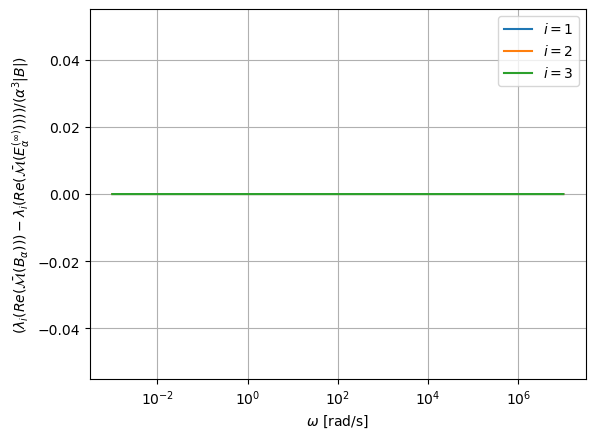

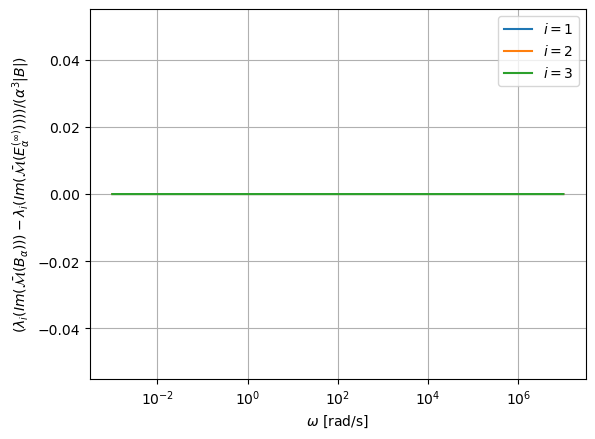

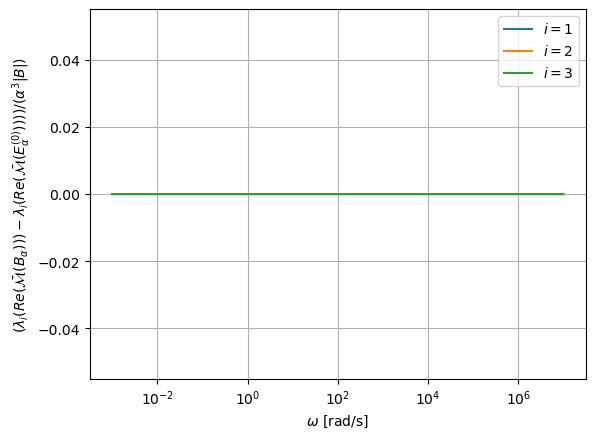

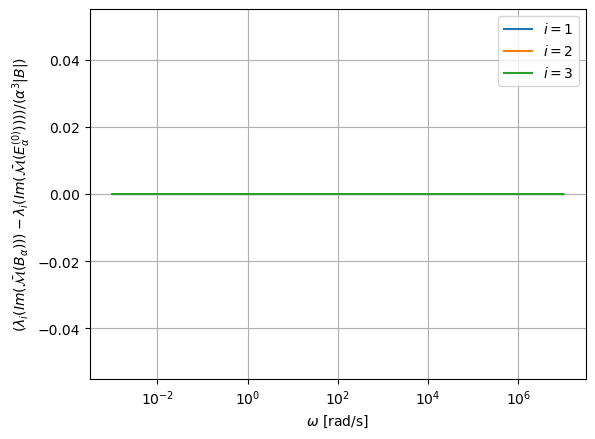

In [4]:
Omega=Omega_db0
diff_Eigenvalues_db0_ellip_minf,diff_Eigenvalues_db0_ellip_n0, d_Eigenvalues_db0_ellip_minf,\
d_Eigenvalues_db0_ellip_n0 = get_tensordiff(TensorArray_db0,TensorArray_db0_ellip_minf,
                                                                                TensorArray_db0_ellip_n0, Omega)

for i in range(3):    
    plt.figure(1)
    plt.semilogx(Omega[0:2000],np.real(diff_Eigenvalues_db0_ellip_minf[0:2000,i])/(alpha**3*vol0),label=r"$i=$"+str(i+1))
   
   
    plt.figure(2)
    plt.semilogx(Omega[0:2000],np.imag(diff_Eigenvalues_db0_ellip_minf[0:2000,i])/(alpha**3*vol0),label=r"$i=$"+str(i+1))

plt.figure(1)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( \infty) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


plt.figure(2)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( \infty) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


for i in range(3):    
    plt.figure(3)
    plt.semilogx(Omega[0:2000],np.real(diff_Eigenvalues_db0_ellip_n0[0:2000,i])/(alpha**3*vol0),label=r"$i=$"+str(i+1))  
   
    plt.figure(4)
    plt.semilogx(Omega[0:2000],np.imag(diff_Eigenvalues_db0_ellip_n0[0:2000,i])/(alpha**3*vol0),label=r"$i=$"+str(i+1))



plt.figure(3)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( 0) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()



plt.figure(4)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( 0) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


In [9]:

# Compare Dumbbell0.2 and N0 and Minf
alpha=0.001
vol2=10.742925374382459

directory="/home/pdl11/Coding/MPT_calculator/July2026/MPT-Calculator/Results/OCC_dumbell_0_2_prism_32/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_67323_ord_3_POD_50_1e-6"
ck_db0_2=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_2=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_2=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_2=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_2= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_2= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_2= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_2=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_2= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_2= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    

directory="Results/OCC_ellipsoid_Dumbbell0_2_Minf/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_66026_ord_4_POD_50_1e-6"
ck_db0_2_ellip_minf=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_2_ellip_minf=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_2_ellip_minf=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_2_ellip_minf=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_2_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_2_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_2_ellip_minf= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_2_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_2_ellip_minf= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_2_ellip_minf= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    

directory="Results/OCC_ellipsoid_Dumbbell0_2_N0/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_66521_ord_3_POD_50_1e-6"
ck_db0_2_ellip_n0=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_2_ellip_n0=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_2_ellip_n0=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_2_ellip_n0=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_2_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_2_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_2_ellip_n0= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_2_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_2_ellip_n0= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_2_ellip_n0= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')  

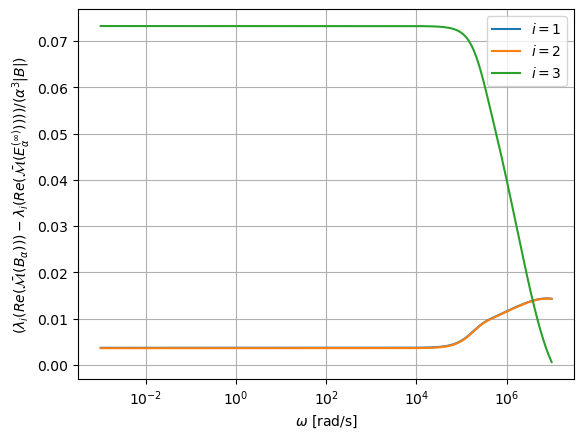

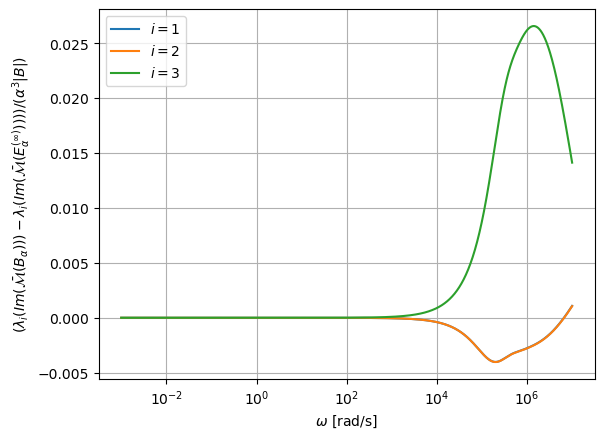

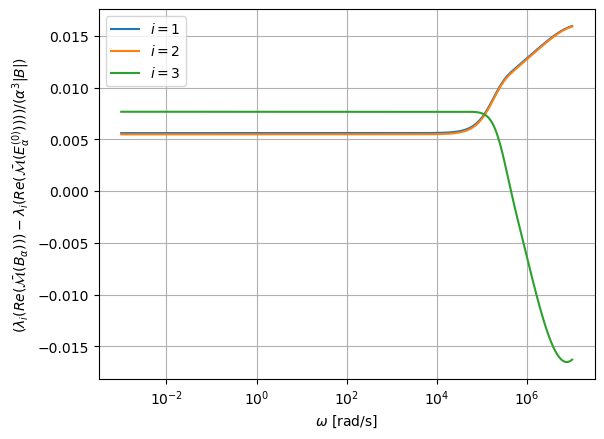

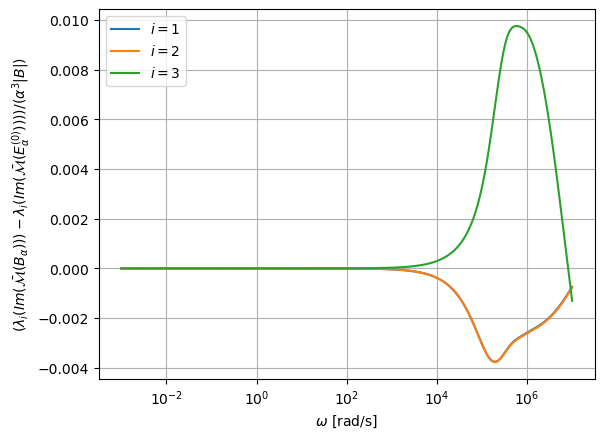

In [10]:
Omega=Omega_db0
diff_Eigenvalues_db0_2_ellip_minf,diff_Eigenvalues_db0_2_ellip_n0, d_Eigenvalues_db0_2_ellip_minf,\
d_Eigenvalues_db0_2_ellip_n0 = get_tensordiff(TensorArray_db0_2,TensorArray_db0_2_ellip_minf,
                                                                                TensorArray_db0_2_ellip_n0, Omega)

for i in range(3):    
    plt.figure(1)
    plt.semilogx(Omega[0:2000],np.real(diff_Eigenvalues_db0_2_ellip_minf[0:2000,i])/(alpha**3*vol2),label=r"$i=$"+str(i+1))
   
   
    plt.figure(2)
    plt.semilogx(Omega[0:2000],np.imag(diff_Eigenvalues_db0_2_ellip_minf[0:2000,i])/(alpha**3*vol2),label=r"$i=$"+str(i+1))

plt.figure(1)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( \infty) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


plt.figure(2)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( \infty) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


for i in range(3):    
    plt.figure(3)
    plt.semilogx(Omega[0:2000],np.real(diff_Eigenvalues_db0_2_ellip_n0[0:2000,i])/(alpha**3*vol2),label=r"$i=$"+str(i+1))  
   
    plt.figure(4)
    plt.semilogx(Omega[0:2000],np.imag(diff_Eigenvalues_db0_2_ellip_n0[0:2000,i])/(alpha**3*vol2),label=r"$i=$"+str(i+1))



plt.figure(3)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( 0) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()



plt.figure(4)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( 0) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()

In [12]:
# Compare Dumbbell0.4 and N0 and Minf
alpha=0.001
vol4=10.742925374382459

directory="/home/pdl11/Coding/MPT_calculator/July2026/MPT-Calculator/Results/OCC_dumbell_0_4_prism_32/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_57985_ord_4_POD_50_1e-6"
ck_db0_4=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_4=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_4=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_4=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_4= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_4= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_4= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_4=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_4= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_4= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    


directory="Results/OCC_ellipsoid_Dumbbell0_4_Minf/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_52996_ord_3_POD_50_1e-6"
ck_db0_4_ellip_minf=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_4_ellip_minf=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_4_ellip_minf=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_4_ellip_minf=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_2_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_4_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_4_ellip_minf= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_4_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_4_ellip_minf= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_4_ellip_minf= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    

directory="Results/OCC_ellipsoid_Dumbbell0_4_N0/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_54417_ord_3_POD_50_1e-6"
ck_db0_4_ellip_n0=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_4_ellip_n0=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_4_ellip_n0=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_4_ellip_n0=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_4_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_4_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_4_ellip_n0= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_4_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_4_ellip_n0= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_4_ellip_n0= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')  

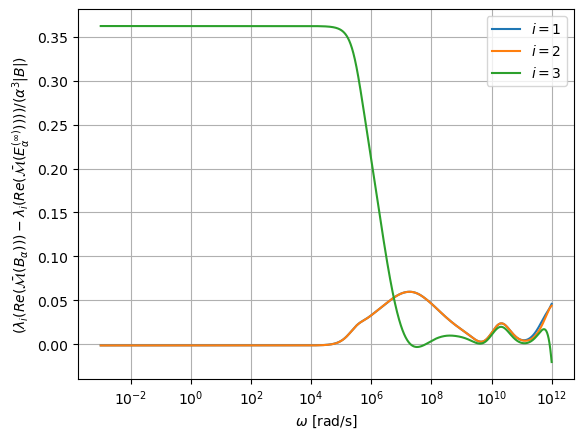

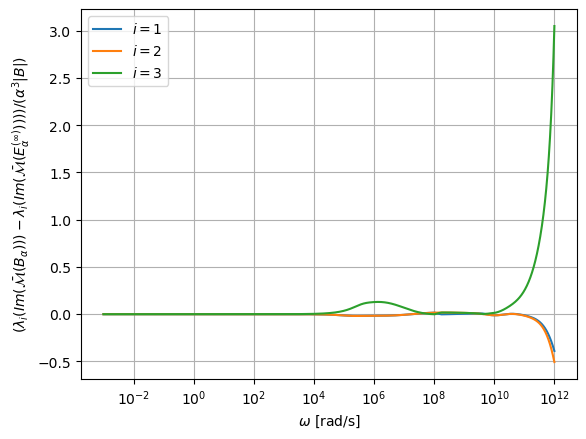

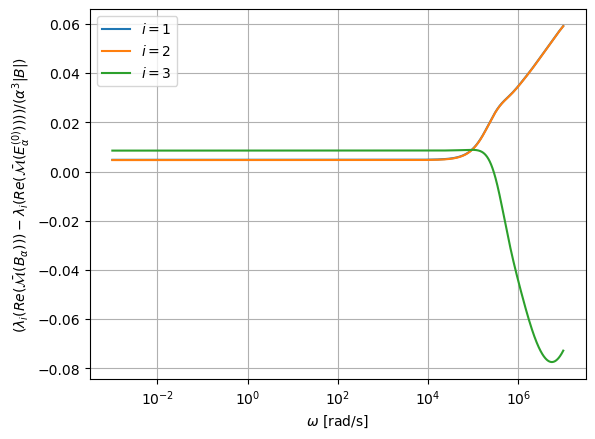

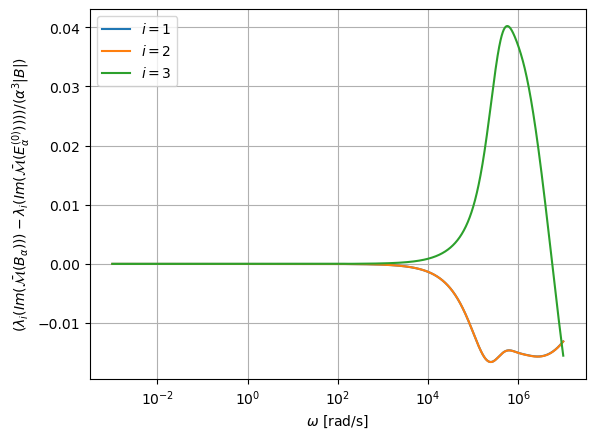

In [13]:
Omega=Omega_db0
diff_Eigenvalues_db0_4_ellip_minf,diff_Eigenvalues_db0_4_ellip_n0, d_Eigenvalues_db0_4_ellip_minf,\
d_Eigenvalues_db0_4_ellip_n0 = get_tensordiff(TensorArray_db0_4,TensorArray_db0_4_ellip_minf,
                                                                                TensorArray_db0_4_ellip_n0, Omega)

for i in range(3):    
    plt.figure(1)
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_4_ellip_minf[:,i])/(alpha**3*vol4),label=r"$i=$"+str(i+1))
    
   
    plt.figure(2)
    plt.semilogx(Omega[:],np.imag(diff_Eigenvalues_db0_4_ellip_minf[:,i])/(alpha**3*vol4),label=r"$i=$"+str(i+1))

plt.figure(1)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( \infty) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


plt.figure(2)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( \infty) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


for i in range(3):    
    plt.figure(3)
    plt.semilogx(Omega[0:2000],np.real(diff_Eigenvalues_db0_4_ellip_n0[0:2000,i])/(alpha**3*vol4),label=r"$i=$"+str(i+1))  
   
    plt.figure(4)
    plt.semilogx(Omega[0:2000],np.imag(diff_Eigenvalues_db0_4_ellip_n0[0:2000,i])/(alpha**3*vol4),label=r"$i=$"+str(i+1))



plt.figure(3)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( 0) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()



plt.figure(4)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( 0) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()

In [14]:
# Compare Dumbbell0.6 and N0 and Minf
alpha=0.001
vol6=5.710256671905834


directory="/home/pdl11/Coding/MPT_calculator/July2026/MPT-Calculator/Results/OCC_dumbell_0_6_prism_32/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_53472_ord_4_POD_50_1e-6"
ck_db0_6_=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_6=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_6=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_4=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_6= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_6= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_6= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_6=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_6= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_6= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    


directory="Results/OCC_ellipsoid_Dumbbell0_6_Minf/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_41202_ord_3_POD_50_1e-6"
ck_db0_6_ellip_minf=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_6_ellip_minf=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_6_ellip_minf=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_6_ellip_minf=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_6_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_6_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_6_ellip_minf= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_6_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_6_ellip_minf= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_6_ellip_minf= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    

directory="Results/OCC_ellipsoid_Dumbbell0_6_N0/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_45508_ord_3_POD_50_1e-6"
ck_db0_6_ellip_n0=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_6_ellip_n0=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_6_ellip_n0=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_6_ellip_n0=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_6_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_6_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_6_ellip_n0= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_6_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_6_ellip_n0= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_6_ellip_n0= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')  

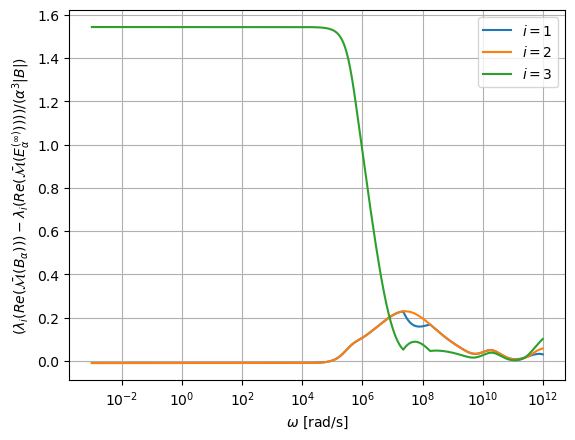

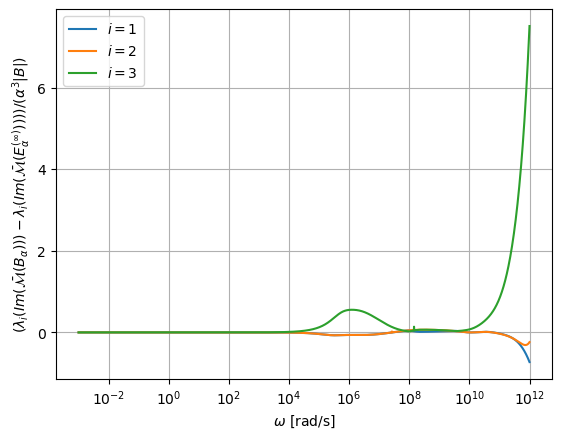

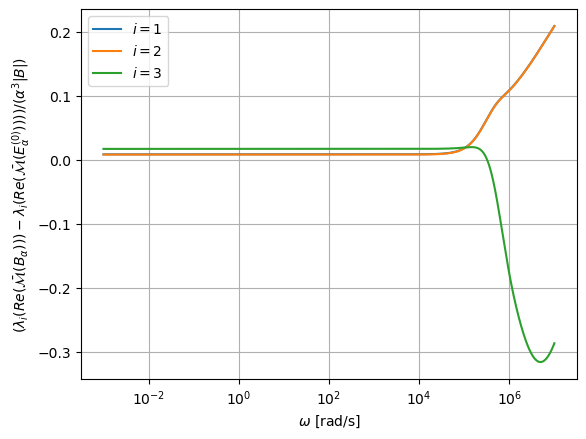

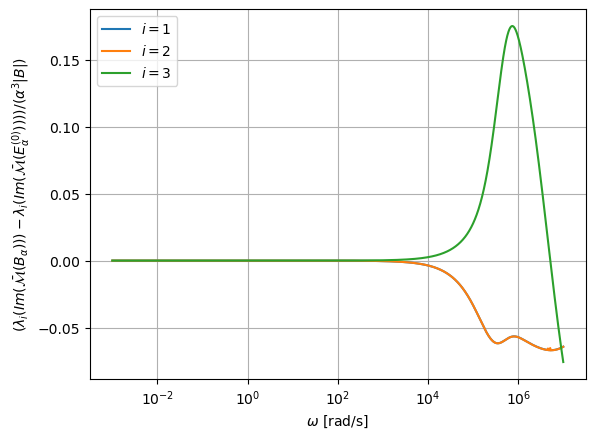

In [15]:
Omega=Omega_db0
diff_Eigenvalues_db0_6_ellip_minf,diff_Eigenvalues_db0_6_ellip_n0, d_Eigenvalues_db0_6_ellip_minf,\
d_Eigenvalues_db0_6_ellip_n0 = get_tensordiff(TensorArray_db0_6,TensorArray_db0_6_ellip_minf,
                                                                                TensorArray_db0_6_ellip_n0, Omega)

for i in range(3):    
    plt.figure(1)
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_6_ellip_minf[:,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1))
    
   
    plt.figure(2)
    plt.semilogx(Omega[:],np.imag(diff_Eigenvalues_db0_6_ellip_minf[:,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1))

plt.figure(1)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( \infty) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


plt.figure(2)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( \infty) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


for i in range(3):    
    plt.figure(3)
    plt.semilogx(Omega[0:2000],np.real(diff_Eigenvalues_db0_6_ellip_n0[0:2000,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1))  
   
    plt.figure(4)
    plt.semilogx(Omega[0:2000],np.imag(diff_Eigenvalues_db0_6_ellip_n0[0:2000,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1))



plt.figure(3)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( 0) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()



plt.figure(4)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( 0) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()

In [19]:
# Compare Dumbbell0.8 and N0 and Minf
alpha=0.001
vol8=4.071761549386107


directory="/home/pdl11/Coding/MPT_calculator/July2026/MPT-Calculator/Results/OCC_dumbell_0_8_prism_32/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_55983_ord_4_POD_50_1e-6"
ck_db0_8_=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_8=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_8=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_8=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_8= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_8= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_8= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_8=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_8= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_8= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    


directory="Results/OCC_ellipsoid_Dumbbell0_8_Minf/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_31553_ord_3_POD_50_1e-6"
ck_db0_8_ellip_minf=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_8_ellip_minf=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_8_ellip_minf=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_6_ellip_minf=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_8_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_8_ellip_minf= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_8_ellip_minf= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_8_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_8_ellip_minf= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_8_ellip_minf= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')    

directory="Results/OCC_ellipsoid_Dumbbell0_8_N0/al_0.001_mu_32_sig_1e6/1e-3-1e12_3000_el_37849_ord_3_POD_50_1e-6"
ck_db0_8_ellip_n0=np.genfromtxt(directory+'/Data/Amplitudes.csv', delimiter=',')
xi_db0_8_ellip_n0=np.genfromtxt(directory+'/Data/Modes.csv', delimiter=',')
Omega_db0_8_ellip_n0=np.genfromtxt(directory+'/Data/Frequencies.csv', delimiter=',')
time_db0_8_ellip_n0=np.genfromtxt(directory+'/Data/Time.csv', delimiter=',')
Sgn_step_db0_8_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_step.csv', delimiter=',')
Sgn_impulse_db0_8_ellip_n0= np.genfromtxt(directory+'/Data/Sgn_impulse.csv', delimiter=',')
TensorArray_db0_8_ellip_n0= np.genfromtxt(directory+'/Data/Tensors.csv', delimiter=',', dtype=complex)
Eigenvalues_db0_8_ellip_minf=np.genfromtxt(directory+'/Data/Eigenvalues.csv', delimiter=',', dtype=complex)
Minf_db0_8_ellip_n0= np.genfromtxt(directory+'/Data/Minf.csv', delimiter=',')
N0_db0_8_ellip_n0= np.genfromtxt(directory+'/Data/N0.csv', delimiter=',')  

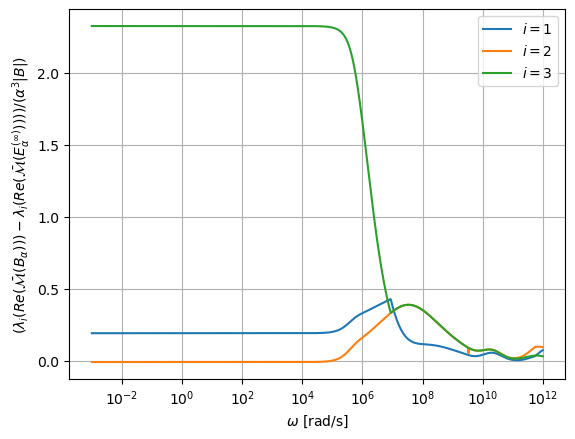

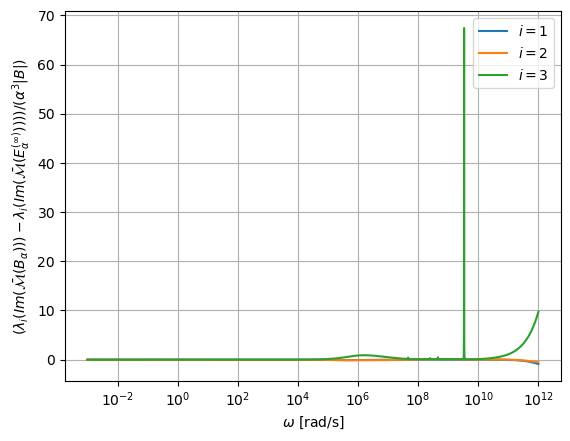

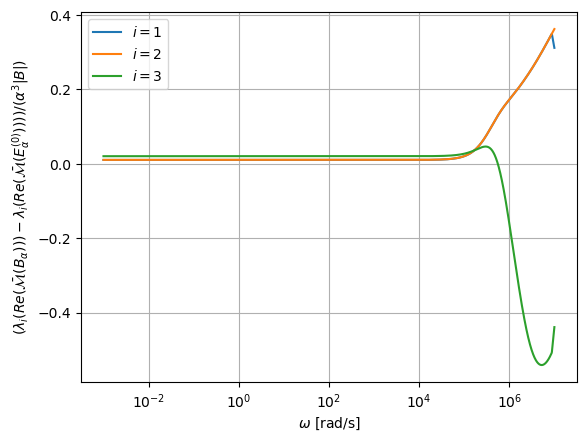

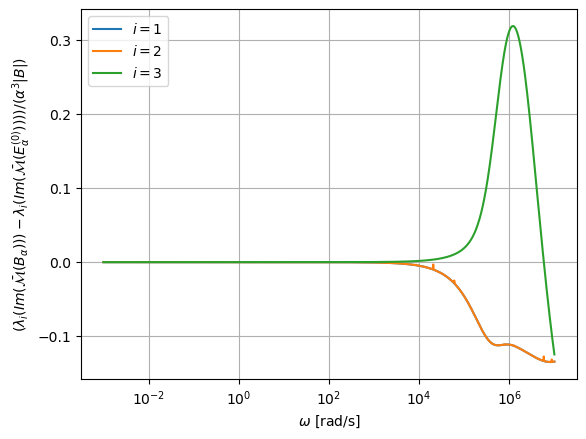

In [20]:
Omega=Omega_db0
diff_Eigenvalues_db0_8_ellip_minf,diff_Eigenvalues_db0_8_ellip_n0, d_Eigenvalues_db0_8_ellip_minf,\
d_Eigenvalues_db0_8_ellip_n0 = get_tensordiff(TensorArray_db0_8,TensorArray_db0_8_ellip_minf,
                                                                                TensorArray_db0_8_ellip_n0, Omega)

for i in range(3):    
    plt.figure(1)
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_8_ellip_minf[:,i])/(alpha**3*vol8),label=r"$i=$"+str(i+1))
    
   
    plt.figure(2)
    plt.semilogx(Omega[:],np.imag(diff_Eigenvalues_db0_8_ellip_minf[:,i])/(alpha**3*vol8),label=r"$i=$"+str(i+1))

plt.figure(1)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( \infty) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


plt.figure(2)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( \infty) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()


for i in range(3):    
    plt.figure(3)
    plt.semilogx(Omega[0:2000],np.real(diff_Eigenvalues_db0_8_ellip_n0[0:2000,i])/(alpha**3*vol8),label=r"$i=$"+str(i+1))  
   
    plt.figure(4)
    plt.semilogx(Omega[0:2000],np.imag(diff_Eigenvalues_db0_8_ellip_n0[0:2000,i])/(alpha**3*vol8),label=r"$i=$"+str(i+1))



plt.figure(3)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( 0) } ) )) ) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()



plt.figure(4)
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( 0) } ) ) )) /(\alpha^3 |B|)$")
plt.grid()
plt.legend()

In [16]:
def yaxis(Omega,y,xmin,xmax,ymin,ymax):
    cnt=0
    for omega in Omega:
        if omega > xmin and omega<xmax:
            if y[cnt]< ymin:
                ymin=y[cnt]
            
            if y[cnt]> ymax:
                ymax=y[cnt]   
        cnt+=1
    return ymin,ymax

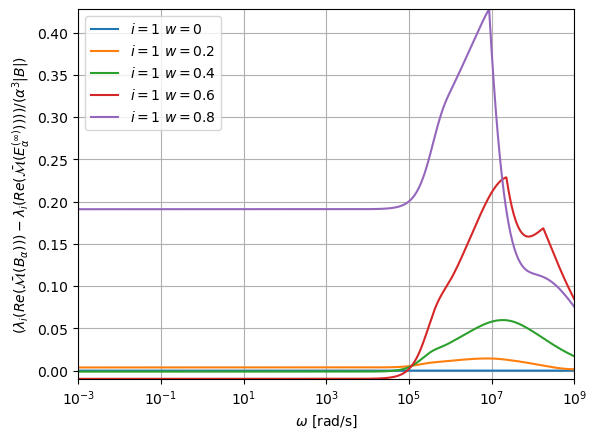

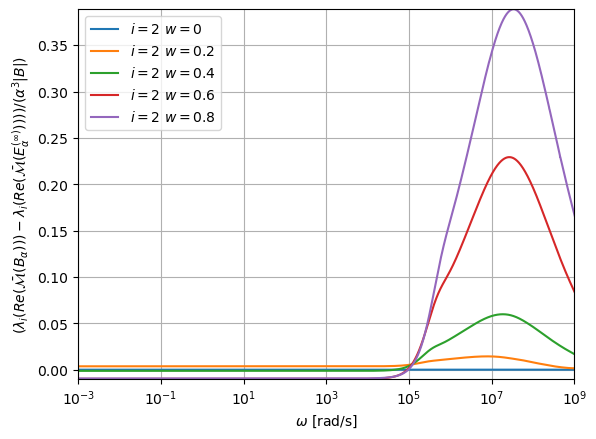

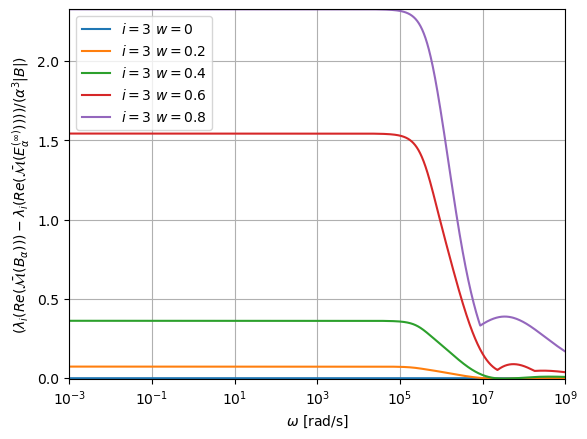

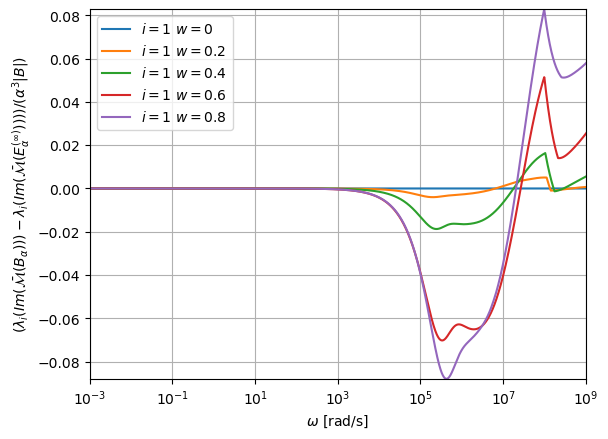

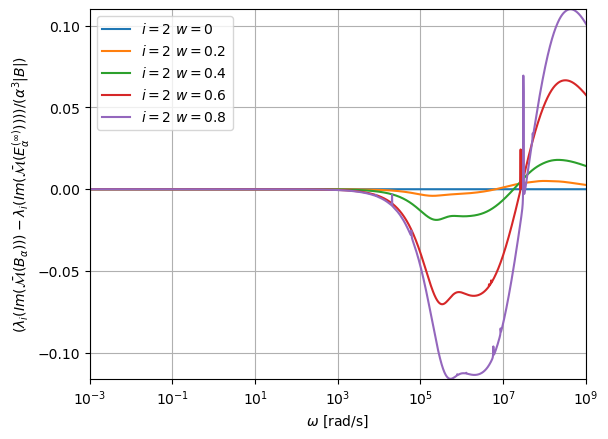

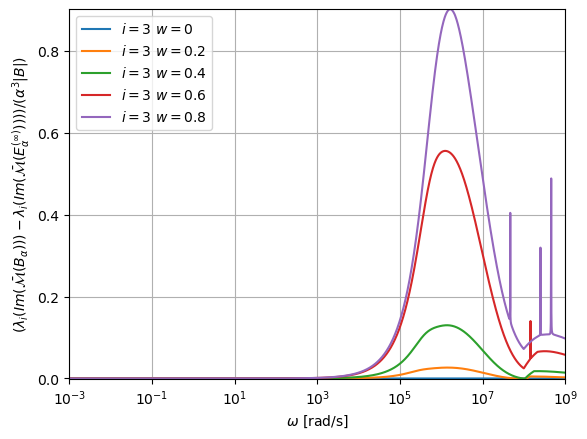

In [28]:
xmin=1e-3
xmax=1e9
ymin=np.zeros(6)
ymax=np.zeros(6)
for i in range(3):    
    plt.figure(i)

    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_ellip_minf[:,i])/(alpha**3*vol0),label=r"$i=$"+str(i+1)+" $w=0$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_ellip_minf[:,i])/(alpha**3*vol0),xmin,xmax,ymin[i],ymax[i])
    
    
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_2_ellip_minf[:,i])/(alpha**3*vol2),label=r"$i=$"+str(i+1)+" $w=0.2$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_2_ellip_minf[:,i])/(alpha**3*vol2),xmin,xmax,ymin[i],ymax[i])
       
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_4_ellip_minf[:,i])/(alpha**3*vol4),label=r"$i=$"+str(i+1)+" $w=0.4$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_4_ellip_minf[:,i])/(alpha**3*vol4),xmin,xmax,ymin[i],ymax[i])
   
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_6_ellip_minf[:,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1)+" $w=0.6$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_6_ellip_minf[:,i])/(alpha**3*vol6),xmin,xmax,ymin[i],ymax[i])

    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_8_ellip_minf[:,i])/(alpha**3*vol8),label=r"$i=$"+str(i+1)+" $w=0.8$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_8_ellip_minf[:,i])/(alpha**3*vol8),xmin,xmax,ymin[i],ymax[i])
   
    
    
    plt.figure(3+i)
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_ellip_minf[:,i])/(alpha**3*vol0),label=r"$i=$"+str(i+1)+" $w=0$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_ellip_minf[:,i])/(alpha**3*vol0),xmin,xmax,ymin[i+3],ymax[i+3])
    
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_2_ellip_minf[:,i])/(alpha**3*vol2),label=r"$i=$"+str(i+1)+" $w=0.2$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_2_ellip_minf[:,i])/(alpha**3*vol2),xmin,xmax,ymin[i+3],ymax[i+3])
    
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_4_ellip_minf[:,i])/(alpha**3*vol4),label=r"$i=$"+str(i+1)+" $w=0.4$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_4_ellip_minf[:,i])/(alpha**3*vol4),xmin,xmax,ymin[i+3],ymax[i+3])

    
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_6_ellip_minf[:,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1)+" $w=0.6$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_6_ellip_minf[:,i])/(alpha**3*vol6),xmin,xmax,ymin[i+3],ymax[i+3])

    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_8_ellip_minf[:,i])/(alpha**3*vol8),label=r"$i=$"+str(i+1)+" $w=0.8$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_8_ellip_minf[:,i])/(alpha**3*vol8),xmin,xmax,ymin[i+3],ymax[i+3])

    
for i in range(3):
    plt.figure(i)
    plt.xlabel(r"$\omega$ [rad/s]")
    plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( \infty) } ) )) ) /(\alpha^3 |B|)$")
    plt.grid()
    plt.legend()
    plt.xlim([xmin,xmax])
    
    plt.ylim([ymin[i],ymax[i]])
    plt.savefig("my_plots/dumbbell/diff_eigenvalues_varyw_minf_re_lam"+str(i+1)+".pdf")
    

for i in range(3):
    plt.figure(i+3)
    plt.xlabel(r"$\omega$ [rad/s]")
    plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( \infty) } ) ) )) /(\alpha^3 |B|)$")
    plt.grid()
    plt.legend()
    plt.xlim([xmin,xmax])
    plt.ylim([ymin[3+i],ymax[3+i]])
    
    plt.savefig("my_plots/dumbbell/diff_eigenvalues_varyw_minf_im_lam"+str(i+1)+".pdf")

plt.show()

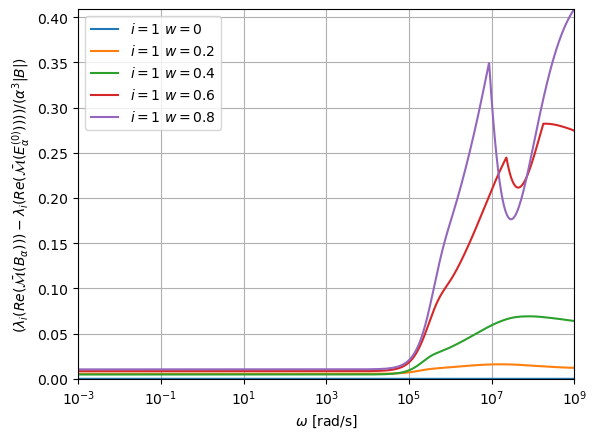

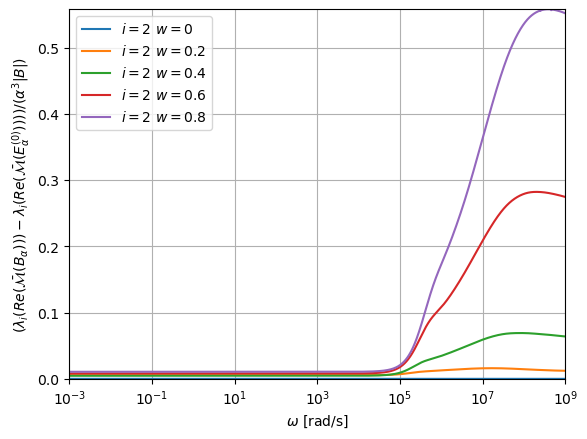

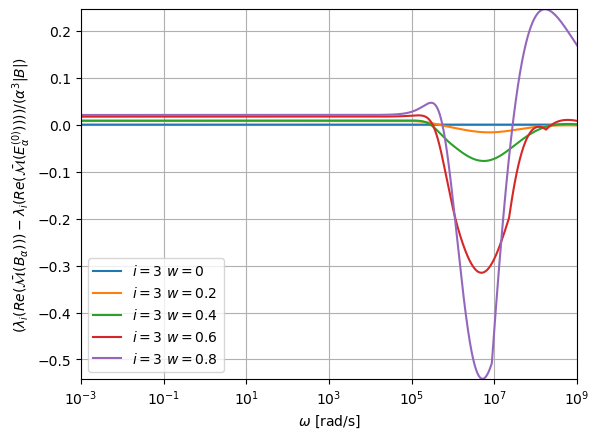

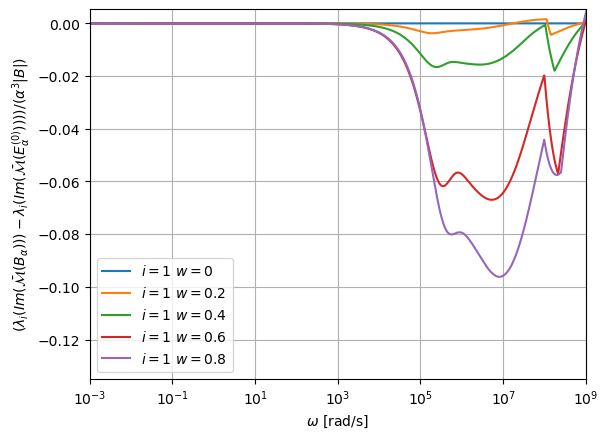

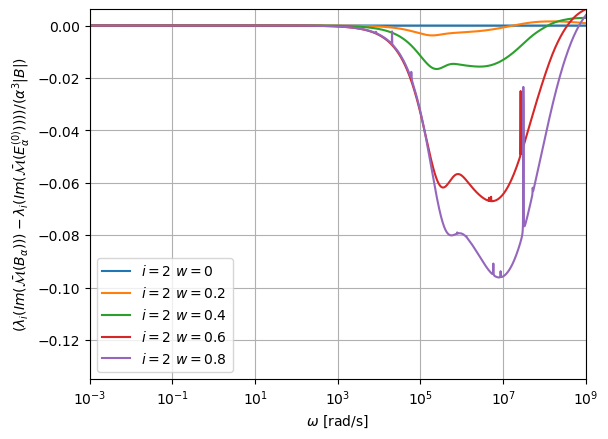

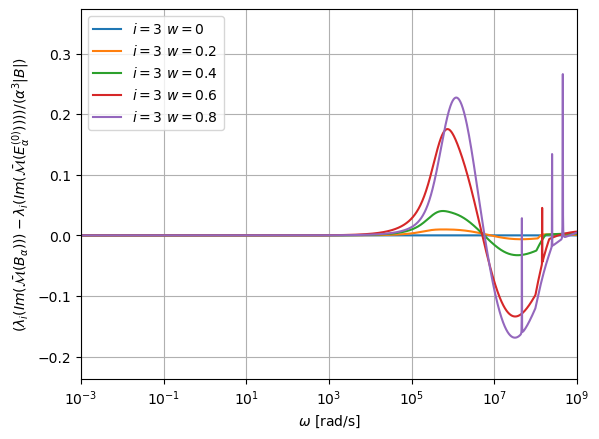

In [26]:
xmin=1e-3
xmax=1e9
ymin=np.zeros(6)
ymax=np.zeros(6)
for i in range(3):    
    plt.figure(i)

    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_ellip_n0[:,i])/(alpha**3*vol0),label=r"$i=$"+str(i+1)+" $w=0$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_ellip_n0[:,i])/(alpha**3*vol0),xmin,xmax,ymin[i],ymax[i])
    
    
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_2_ellip_n0[:,i])/(alpha**3*vol2),label=r"$i=$"+str(i+1)+" $w=0.2$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_2_ellip_n0[:,i])/(alpha**3*vol2),xmin,xmax,ymin[i],ymax[i])
       
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_4_ellip_n0[:,i])/(alpha**3*vol4),label=r"$i=$"+str(i+1)+" $w=0.4$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_4_ellip_n0[:,i])/(alpha**3*vol4),xmin,xmax,ymin[i],ymax[i])
   
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_6_ellip_n0[:,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1)+" $w=0.6$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_6_ellip_n0[:,i])/(alpha**3*vol6),xmin,xmax,ymin[i],ymax[i])

    
    plt.semilogx(Omega,np.real(diff_Eigenvalues_db0_8_ellip_n0[:,i])/(alpha**3*vol8),label=r"$i=$"+str(i+1)+" $w=0.8$")
    ymin[i],ymax[i]=yaxis(Omega,np.real(diff_Eigenvalues_db0_8_ellip_n0[:,i])/(alpha**3*vol8),xmin,xmax,ymin[i],ymax[i])
   

    plt.figure(3+i)
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_ellip_n0[:,i])/(alpha**3*vol0),label=r"$i=$"+str(i+1)+" $w=0$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_ellip_n0[:,i])/(alpha**3*vol0),xmin,xmax,ymin[i+3],ymax[i+3])
    
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_2_ellip_n0[:,i])/(alpha**3*vol2),label=r"$i=$"+str(i+1)+" $w=0.2$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_2_ellip_n0[:,i])/(alpha**3*vol2),xmin,xmax,ymin[i+3],ymax[i+3])
    
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_4_ellip_n0[:,i])/(alpha**3*vol4),label=r"$i=$"+str(i+1)+" $w=0.4$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_4_ellip_n0[:,i])/(alpha**3*vol4),xmin,xmax,ymin[i+3],ymax[i+3])
    
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_6_ellip_n0[:,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1)+" $w=0.6$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_6_ellip_n0[:,i])/(alpha**3*vol6),xmin,xmax,ymin[i+3],ymax[i+3])
    
    plt.semilogx(Omega,np.imag(diff_Eigenvalues_db0_8_ellip_n0[:,i])/(alpha**3*vol6),label=r"$i=$"+str(i+1)+" $w=0.8$")
    ymin[3+i],ymax[3+i]=yaxis(Omega,np.imag(diff_Eigenvalues_db0_8_ellip_n0[:,i])/(alpha**3*vol8),xmin,xmax,ymin[i+3],ymax[i+3])
    
    
for i in range(3):
    plt.figure(i)
    plt.xlabel(r"$\omega$ [rad/s]")
    plt.ylabel(r"$(\lambda_i ( Re(\bar{\cal M} (B_\alpha )) )- \lambda_i (Re(\bar{\cal M} ( E_\alpha^{( 0) } ) )) ) /(\alpha^3 |B|)$")
    plt.grid()
    plt.legend()
    plt.xlim([xmin,xmax])
    
    plt.ylim([ymin[i],ymax[i]])
    plt.savefig("my_plots/dumbbell/diff_eigenvalues_varyw_n0_re_lam"+str(i+1)+".pdf")

    

for i in range(3):
    plt.figure(i+3)
    plt.xlabel(r"$\omega$ [rad/s]")
    plt.ylabel(r"$(\lambda_i ( Im(\bar{\cal M} (B_\alpha )) )- \lambda_i (Im(\bar{\cal M} ( E_\alpha^{( 0) } ) ) )) /(\alpha^3 |B|)$")
    plt.grid()
    plt.legend()
    plt.xlim([xmin,xmax])
    plt.ylim([ymin[3+i],ymax[3+i]])
    plt.savefig("my_plots/dumbbell/diff_eigenvalues_varyw_n0_im_lam"+str(i+1)+".pdf")

plt.show()